# Word2Vec Skip-gram: With vs Without Negative Sampling

This notebook implements **Skip-gram** in two ways:

1. **With Negative Sampling** (fast, used in real Word2Vec)
2. **Without Negative Sampling** (full Softmax)

We also visualize the learned embeddings using 2-D PCA.

## 1. Common Setup (Corpus + Vocabulary)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Corpus
corpus = [
    "cats like milk",
    "cats drink milk",
    "dogs like milk",
    "dogs chase balls",
    "cats chase balls"
]

# Build vocabulary
sentences = [s.split() for s in corpus]
vocab = sorted(set(word for s in sentences for word in s))
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}
V = len(vocab)

print("Vocabulary:", vocab)
print("Vocab size V =", V)

# Hyperparameters (shared)
window = 1
d = 3                 # embedding dimension
learning_rate = 0.05
epochs = 500

# Generate positive center-context pairs
pairs = []
for sentence in sentences:
    ids = [word_to_id[w] for w in sentence]
    for i, center in enumerate(ids):
        for j in range(max(0, i - window), min(len(ids), i + window + 1)):
            if i != j:
                pairs.append((center, ids[j]))

print("Number of positive pairs:", len(pairs))
print("Pairs:", [(id_to_word[c], id_to_word[ctx]) for c, ctx in pairs])

Vocabulary: ['balls', 'cats', 'chase', 'dogs', 'drink', 'like', 'milk']
Vocab size V = 7
Number of positive pairs: 20
Pairs: [('cats', 'like'), ('like', 'cats'), ('like', 'milk'), ('milk', 'like'), ('cats', 'drink'), ('drink', 'cats'), ('drink', 'milk'), ('milk', 'drink'), ('dogs', 'like'), ('like', 'dogs'), ('like', 'milk'), ('milk', 'like'), ('dogs', 'chase'), ('chase', 'dogs'), ('chase', 'balls'), ('balls', 'chase'), ('cats', 'chase'), ('chase', 'cats'), ('chase', 'balls'), ('balls', 'chase')]


## 2. Skip-gram **WITH** Negative Sampling

In [2]:
K = 3   # number of negative samples per positive pair

np.random.seed(42)
E_neg = np.random.randn(V, d) * 0.1   # input (center) embeddings
W_neg = np.random.randn(V, d) * 0.1   # output (context) embeddings

# Negative sampling distribution (freq^0.75)
counts = np.zeros(V)
for sentence in sentences:
    for word in sentence:
        counts[word_to_id[word]] += 1
neg_probs = counts ** 0.75
neg_probs /= neg_probs.sum()

def sample_negatives(context, K):
    negatives = []
    while len(negatives) < K:
        word = np.random.choice(V, p=neg_probs)
        if word != context:
            negatives.append(word)
    return negatives

def sigmoid(x):
    x = np.clip(x, -15, 15)
    return 1.0 / (1.0 + np.exp(-x))

losses_neg = []

for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0.0

    for center, context in pairs:
        v = E_neg[center]

        # Positive pair
        u_pos = W_neg[context]
        score_pos = np.dot(v, u_pos)
        total_loss += np.logaddexp(0.0, -score_pos)

        grad_score_pos = sigmoid(score_pos) - 1.0
        grad_v = grad_score_pos * u_pos
        grad_u_pos = grad_score_pos * v

        # Negative pairs
        negatives = sample_negatives(context, K)
        for neg in negatives:
            u_neg = W_neg[neg]
            score_neg = np.dot(v, u_neg)
            total_loss += np.logaddexp(0.0, score_neg)

            grad_score_neg = sigmoid(score_neg)
            grad_v += grad_score_neg * u_neg
            W_neg[neg] -= learning_rate * (grad_score_neg * v)

        # Update
        E_neg[center] -= learning_rate * grad_v
        W_neg[context] -= learning_rate * grad_u_pos

    losses_neg.append(total_loss / len(pairs))

print("Learned embeddings (WITH Negative Sampling):")
for word, idx in word_to_id.items():
    print(f"{word:8s}: {np.round(E_neg[idx], 3)}")

Learned embeddings (WITH Negative Sampling):
balls   : [ 4.509 -1.487  0.23 ]
cats    : [ 0.566 -1.516  0.397]
chase   : [1.84  1.234 1.335]
dogs    : [ 1.641 -2.418  0.833]
drink   : [-0.483  0.376  2.844]
like    : [-0.397  0.44   1.875]
milk    : [-0.402 -2.946  1.78 ]


## 3. Skip-gram **WITHOUT** Negative Sampling (Full Softmax)

In [3]:
np.random.seed(42)
E_full = np.random.randn(V, d) * 0.1   # input embeddings (V x d)
W_full = np.random.randn(d, V) * 0.1   # output weights (d x V)

def softmax(x):
    x = x - np.max(x)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

losses_full = []

for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0.0

    for center, context in pairs:
        h = E_full[center]
        scores = h @ W_full
        probs = softmax(scores)

        loss = -np.log(probs[context] + 1e-12)
        total_loss += loss

        error = probs.copy()
        error[context] -= 1

        grad_W = np.outer(h, error)
        grad_h = W_full @ error

        W_full -= learning_rate * grad_W
        E_full[center] -= learning_rate * grad_h

    losses_full.append(total_loss / len(pairs))

print("Learned embeddings (WITHOUT Negative Sampling - Full Softmax):")
for word, idx in word_to_id.items():
    print(f"{word:8s}: {np.round(E_full[idx], 3)}")

Learned embeddings (WITHOUT Negative Sampling - Full Softmax):
balls   : [-1.23  -2.008 -1.94 ]
cats    : [ 0.013 -1.343  0.419]
chase   : [ 1.048  0.352 -1.393]
dogs    : [-1.841 -1.039  0.158]
drink   : [1.123 1.574 1.196]
like    : [-0.444  1.595 -0.06 ]
milk    : [-0.357 -0.656  2.014]


## 4. Training Loss Comparison

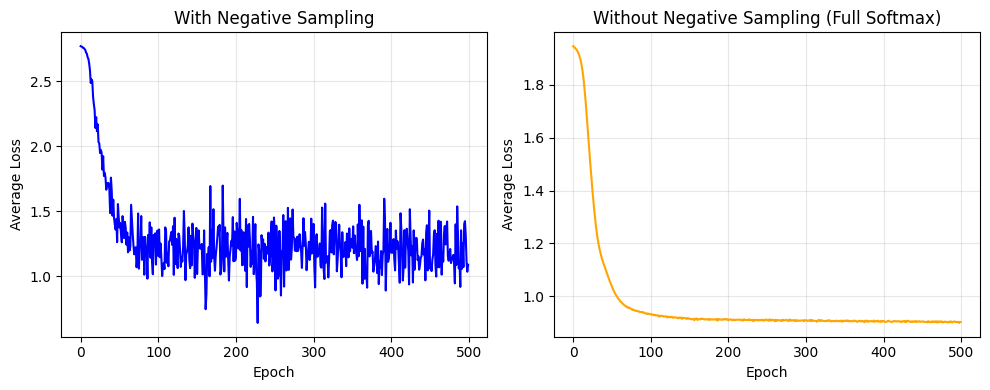

In [4]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(losses_neg, color='blue')
plt.title("With Negative Sampling")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(losses_full, color='orange')
plt.title("Without Negative Sampling (Full Softmax)")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. 2-D PCA Visualization of Embeddings

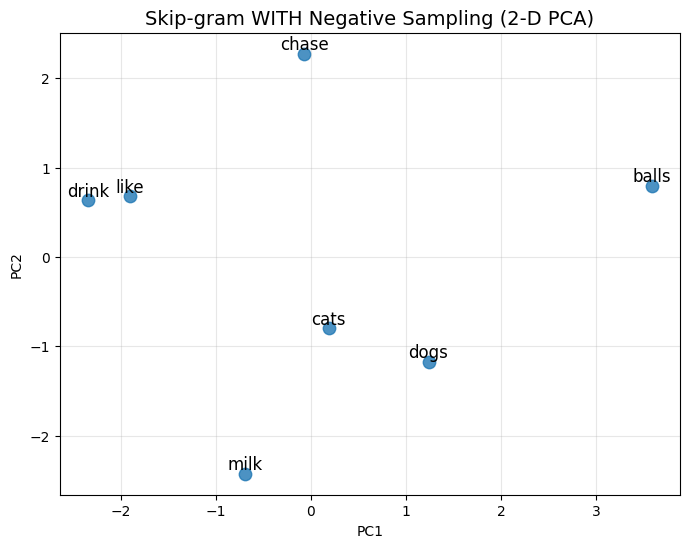

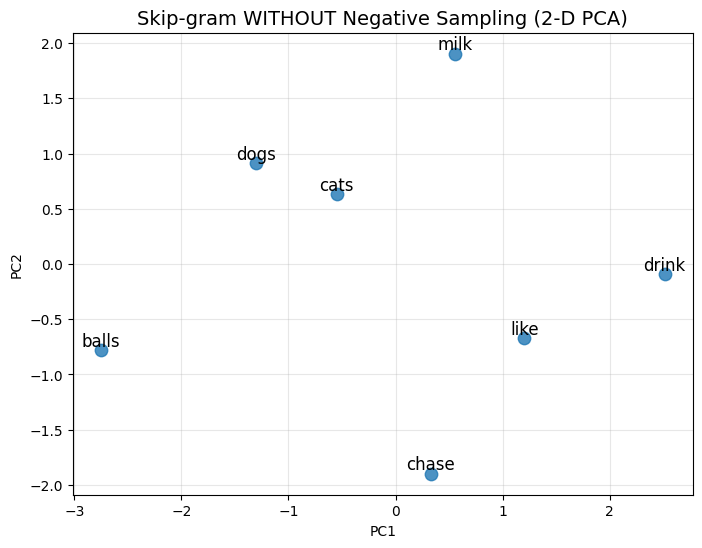

In [5]:
def plot_pca(embeddings, title):
    pca = PCA(n_components=2)
    coords = pca.fit_transform(embeddings)

    plt.figure(figsize=(8, 6))
    plt.scatter(coords[:, 0], coords[:, 1], s=80, alpha=0.8)

    for i, word in id_to_word.items():
        plt.annotate(word, (coords[i, 0], coords[i, 1]),
                     fontsize=12, ha='center', va='bottom')

    plt.title(title, fontsize=14)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(True, alpha=0.3)
    plt.show()

plot_pca(E_neg, "Skip-gram WITH Negative Sampling (2-D PCA)")
plot_pca(E_full, "Skip-gram WITHOUT Negative Sampling (2-D PCA)")

## 6. Cosine Similarity Check

In [6]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)

def similar_words(embeddings, word, top_k=3):
    idx = word_to_id[word]
    scores = []
    for j in range(V):
        if j != idx:
            sim = cosine_similarity(embeddings[idx], embeddings[j])
            scores.append((id_to_word[j], sim))
    return sorted(scores, key=lambda x: x[1], reverse=True)[:top_k]

print("=== WITH Negative Sampling ===")
print("Similar to 'cats':", similar_words(E_neg, "cats"))
print("Similar to 'dogs':", similar_words(E_neg, "dogs"))

print("\n=== WITHOUT Negative Sampling (Full Softmax) ===")
print("Similar to 'cats':", similar_words(E_full, "cats"))
print("Similar to 'dogs':", similar_words(E_full, "dogs"))

=== WITH Negative Sampling ===
Similar to 'cats': [('dogs', np.float64(0.9727592006343692)), ('milk', np.float64(0.8565178316804304)), ('balls', np.float64(0.6182585404517025))]
Similar to 'dogs': [('cats', np.float64(0.9727592006343692)), ('balls', np.float64(0.7744498845906281)), ('milk', np.float64(0.7546093355092928))]

=== WITHOUT Negative Sampling (Full Softmax) ===
Similar to 'cats': [('milk', np.float64(0.5694120567772718)), ('dogs', np.float64(0.48216726735138926)), ('balls', np.float64(0.4349295002418639))]
Similar to 'dogs': [('balls', np.float64(0.6255228437587221)), ('cats', np.float64(0.48216726735138926)), ('milk', np.float64(0.36398168414484044))]


## 7. Key Differences

| Feature                        | **With Negative Sampling**                          | **Without (Full Softmax)**                      |
|--------------------------------|-----------------------------------------------------|-------------------------------------------------|
| **Output computation**         | Only 1 positive + K negatives                       | Softmax over **entire vocabulary**              |
| **Speed**                      | Very fast (even for large vocab)                    | Slow when vocabulary is large                   |
| **Loss function**              | Binary logistic loss (sigmoid)                      | Multi-class cross-entropy                       |
| **Gradient updates**           | Only updates a few vectors per example              | Updates all output weights every step           |
| **Used in practice?**          | Yes (original Word2Vec paper, gensim, etc.)         | Only for teaching / very small vocabularies     |
| **Quality**                    | Almost as good as full softmax                      | Theoretically exact, but expensive              |

### Summary

- **Negative Sampling** is an approximation that makes training practical on large vocabularies.
- **Full Softmax** is exact but becomes too slow when the vocabulary has tens of thousands of words.
- On this tiny corpus both methods learn similar relationships (cats ↔ dogs, milk, etc.).